# 9. Datos: ficha técnica, contrato de datos y auditoría de fuga

En este capítulo ampliamos el análisis de datos de los capítulos 1 y 2 para los diez modelos del benchmark. Presentamos la ficha técnica del conjunto de datos y su contrato, resumimos el EDA en una tabla de trazabilidad entre hallazgos y decisiones, y ejecutamos la auditoría de fuga de información. Cada verificación se calcula en este cuaderno a partir de la partición, de las imágenes y de las predicciones guardadas; ninguna celda entrena redes profundas.

In [1]:
import sys
import json
import hashlib
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "entregable2" / "src").exists())
E2 = ROOT / "entregable2"
for p in (E2 / "analisis", E2):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown
from scipy import stats as st

import figuras as FG
from comun import CLASSES, MODELS, SEEDS, aligned, fast_f1_macro, split_table

FG.setup()
pd.set_option("display.precision", 4)
RAW = ROOT / "data" / "raw" / "trashnet" / "dataset-resized"
COMP = E2 / "results" / "complementario"
split = split_table().copy()
print(f"Imágenes en la partición v2: {len(split)} | grupos: {split.group.nunique()} | imágenes disponibles localmente: {RAW.exists()}")

Imágenes en la partición v2: 2521 | grupos: 2512 | imágenes disponibles localmente: True


## 9.1 Ficha técnica (*Data Card*)

| Campo | Descripción |
|---|---|
| Nombre y versión | TrashNet (Yang y Thung, 2016; Thung, 2017), versión `dataset-resized` de 512×384 píxeles |
| Procedencia | Curso CS229 de la Universidad de Stanford, 2016–2017. Un objeto por fotografía sobre una cartulina blanca, con luz solar o de interior, tomada con tres teléfonos (iPhone 7 Plus, iPhone 5S e iPhone SE) |
| Licencia | MIT (repositorio `garythung/trashnet`); permite uso académico y redistribución con el aviso de copyright |
| Tamaño y estructura | 2527 imágenes JPEG RGB de 8 bits en seis carpetas; 2521 tras eliminar 3 pares idénticos con etiqueta contradictoria (sección 2.3) |
| Variable objetivo | Material del objeto, seis clases nominales: `cardboard` 403, `glass` 498, `metal` 409, `paper` 594, `plastic` 480 y `trash` 137 |
| Protocolo de etiquetado | Manual, por los dos autores, al fotografiar el objeto. No hay segunda anotación ni medida de acuerdo entre anotadores |
| Ruido de etiqueta | Esperado en materiales mixtos, en pares visualmente parecidos (vidrio y plástico, papel y cartón) y en `trash`. Lo estimamos con la taxonomía de errores y el techo de desempeño (secciones 15.3 y 15.4) |
| Cobertura | Objetos domésticos de Estados Unidos, fotografiados en estudio. No representa residuos sucios, deformados, superpuestos ni en banda transportadora |
| Privacidad y ética | Sin personas ni datos personales. El riesgo principal es de uso: un clasificador entrenado en estudio puede fallar en plantas de reciclaje y desviar material reciclable a rechazo |
| Licencias de los modelos | Código de torchvision con licencia BSD-3; los pesos preentrenados en ImageNet-1k se usan con fines de investigación, conforme a los términos de ImageNet. El código oficial de Celik-HC es público en GitHub |
| Disparidad de error | Las clases no son grupos de personas, pero el error no es uniforme: `trash` y `plastic` concentran los fallos (sección 13.3). En un despliegue, el plástico clasificado como vidrio contaminaría la línea de vidrio, y el rechazo de reciclables aumentaría los residuos a disposición final |
| Integridad | SHA-256 de cada imagen en la partición; huella del conjunto de prueba `4e4651dc…cbd87` verificada antes de cada corrida (sección 9.4) |
| Partición | `data/splits/trashnet_split_v2_s1234.csv`, semilla 1234, estratificada por clase y agrupada por casi-duplicados: 1800 / 360 / 361 |

**Partición oficial.** TrashNet no publica una partición oficial. Los estudios revisados usan particiones aleatorias distintas (80/20, 70/13/17, validación cruzada), que no controlan los casi-duplicados. Por eso mantenemos la partición agrupada del capítulo 2. Para la réplica del paper guía (capítulo 12) usamos además su partición 80/20 original, solo con ese fin.

## 9.2 Contrato de datos

El contrato fija qué debe cumplir cada observación al cargarse. El código del benchmark (`entregable2/src/data.py`) lo verifica antes de cada corrida y detiene la ejecución si alguna regla falla.

| Elemento | Regla verificada |
|---|---|
| Esquema de la partición | Columnas `relpath`, `label`, `label_id`, `sha256`, `group`, `split`; `label_id` en $\{0,\dots,5\}$ y coherente con la carpeta; `split` en {train, val, test} |
| Integridad | El SHA-256 de cada archivo coincide con el registrado; la huella del conjunto de prueba coincide con `data/SHA256SUMS.txt` |
| Formato de imagen | JPEG decodificable, RGB, 512×384 |
| Transformaciones | Redimensionamiento bicúbico a 224×224 y conversión a tensor; normalización con estadísticas de entrenamiento (modelos desde cero) o de ImageNet (modelos preentrenados) |
| Poblaciones | Se excluyen 6 imágenes con etiqueta contradictoria; ningún otro filtro. Entrenamiento 1800, validación 360 y prueba 361 |

La celda siguiente ejecuta las reglas del esquema y de la población sobre la partición.

In [2]:
reglas = {
    "columnas esperadas": list(split.columns) == ["relpath", "label", "label_id", "sha256", "group", "split"],
    "label_id en 0..5 y coherente con la carpeta": bool(((split.label_id.between(0, 5))
        & (split.label == split.relpath.str.split("/").str[0])
        & (split.label.map({c: i for i, c in enumerate(CLASSES)}) == split.label_id)).all()),
    "split en {train, val, test}": set(split.split) == {"train", "val", "test"},
    "tamaños 1800 / 360 / 361": split.split.value_counts().to_dict() == {"train": 1800, "test": 361, "val": 360},
    "sin rutas repetidas": split.relpath.is_unique,
}
display(pd.DataFrame({"regla": list(reglas), "cumple": list(reglas.values())}))

,regla,cumple
0,columnas esperadas,True
1,label_id en 0..5 y coherente con la carpeta,True
2,"split en {train, val, test}",True
3,tamaños 1800 / 360 / 361,True
4,sin rutas repetidas,True


## 9.3 EDA orientado a decisiones

El análisis exploratorio completo está en el capítulo 2. Aquí resumimos los hallazgos que condicionan el benchmark y añadimos tres análisis nuevos: el efecto de la normalización de ImageNet en los modelos preentrenados, la distribución de clases por partición y el desplazamiento entre particiones medido con descriptores clásicos.

In [3]:
tab = pd.crosstab(split.label, split.split)[["train", "val", "test"]]
tab["total"] = tab.sum(1)
p = tab["total"] / tab["total"].sum()
display(tab)
H = -(p * np.log(p)).sum() / np.log(len(p))
chi = st.chi2_contingency(tab[["train", "val", "test"]])
print(f"Razón de desbalance (paper/trash): {tab.total.max() / tab.total.min():.2f} | entropía normalizada: {H:.3f}")
print(f"Homogeneidad de clases entre particiones: chi2 = {chi.statistic:.2f}, gl = {chi.dof}, p = {chi.pvalue:.3f}")

C:\Users\User\AppData\Local\Temp\ipykernel_15504\2454551259.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  tab["total"] = tab.sum(1)


split,train,val,test,total
label,,,,
cardboard,287,58,58,403
glass,355,71,72,498
metal,292,59,58,409
paper,424,85,85,594
plastic,343,68,69,480
trash,99,19,19,137


Razón de desbalance (paper/trash): 4.34 | entropía normalizada: 0.962
Homogeneidad de clases entre particiones: chi2 = 0.08, gl = 10, p = 1.000


**Desplazamiento entre particiones (validación adversarial).** Entrenamos un clasificador que intenta distinguir las imágenes de entrenamiento de las de prueba a partir de descriptores de color y de gradiente (los mismos del baseline clásico, sección 13.4). Si las particiones provienen de la misma distribución, su AUC no debe diferir de 0.5. El $p$ se obtiene permutando la etiqueta de partición 200 veces.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

feat = np.load(COMP / "_features_clasicas.npz", allow_pickle=True)
Xf = pd.DataFrame(feat["X"], index=feat["relpath"])
sp_sorted = split.set_index("relpath").loc[Xf.index]

def auc_adversarial(a, b, n_perm=200, seed=0):
    m = sp_sorted.split.isin([a, b]).to_numpy()
    X, y = Xf.to_numpy()[m], (sp_sorted.split.to_numpy()[m] == b).astype(int)
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000))
    cv = StratifiedKFold(5, shuffle=True, random_state=seed)
    auc = roc_auc_score(y, cross_val_predict(clf, X, y, cv=cv, method="predict_proba")[:, 1])
    rng = np.random.default_rng(seed)
    null = []
    for _ in range(n_perm):
        yp = rng.permutation(y)
        null.append(roc_auc_score(yp, cross_val_predict(clf, X, yp, cv=cv, method="predict_proba")[:, 1]))
    return auc, (1 + np.sum(np.array(null) >= auc)) / (n_perm + 1)

adv = pd.DataFrame([{"par": f"{a} frente a {b}", "AUC": r[0], "p_permutación": r[1]}
                    for a, b in [("train", "test"), ("train", "val"), ("val", "test")]
                    for r in [auc_adversarial(a, b)]])
display(adv)

,par,AUC,p_permutación
0,train frente a test,0.4996,0.4726
1,train frente a val,0.4728,0.8905
2,val frente a test,0.5598,0.0149


Entrenamiento y prueba, y entrenamiento y validación, no se distinguen (AUC ≈ 0.5). Validación y prueba sí se separan levemente (AUC 0.56, $p = 0.015$; $p = 0.045$ con Holm sobre las tres parejas). Es una diferencia pequeña entre dos conjuntos de unas 360 imágenes, pero obliga a interpretar con cautela la brecha entre validación y prueba de la sección 14.2: parte de ella puede deberse a la composición de los conjuntos y no solo a la selección de hiperparámetros.

**Normalización de los modelos preentrenados.** Los modelos con pesos de ImageNet se normalizan con la media y la desviación estándar de ImageNet, porque sus filtros se aprendieron con esa escala. La tabla compara esas estadísticas con las de nuestro conjunto de entrenamiento: el fondo blanco eleva la media de los tres canales de TrashNet a cerca de 0.6–0.7, por encima de la de ImageNet. La diferencia desplaza la entrada de los modelos preentrenados, pero es la misma para entrenamiento, validación y prueba, y no introduce fuga.

In [5]:
import pickle
norm = pickle.load(open(E2 / "results" / "common" / "norm_stats.pkl", "rb"))
display(pd.DataFrame({"canal": ["R", "G", "B"], "media_train": norm["mean"], "de_train": norm["std"],
                      "media_imagenet": [0.485, 0.456, 0.406], "de_imagenet": [0.229, 0.224, 0.225]}))
print("Calculadas sobre:", norm.get("computed_on"), "| tamaño:", norm.get("size"))

,canal,media_train,de_train,media_imagenet,de_imagenet
0,R,0.6718,0.2091,0.485,0.229
1,G,0.6380,0.2093,0.456,0.224
2,B,0.6022,0.2309,0.406,0.225


Calculadas sobre: train | tamaño: 224


### Tabla de trazabilidad hallazgo–decisión (Apéndice A.1)

| Hallazgo | Evidencia | Decisión de preprocesamiento | Impacto en arquitectura o validación | Riesgo y fuga |
|---|---|---|---|---|
| Desbalance 4.34:1 (`paper` frente a `trash`); entropía normalizada 0.96 | Tabla de conteos (sección 2.2 y celda anterior) | Pérdida ponderada $w_k = N/(K n_k)$ en los diez modelos, también en las pérdidas propias | Métrica primaria F1 macro; balanced accuracy y MCC como secundarias | Optimizar accuracy favorecería a `paper`; sin *oversampling*, que podría duplicar imágenes entre lotes |
| 3 pares idénticos con etiquetas distintas | Hash SHA-256 (sección 2.3) | Eliminar las 6 imágenes | Ninguno | Si quedan en prueba, ponen un error irreducible; si se dividen, filtran la imagen |
| Casi-duplicados (2521 imágenes en 2512 grupos) | Hash perceptual (sección 2.4) y auditoría 9.4 con *embeddings*, que además encuentra vistas distintas de un mismo objeto en particiones distintas | Agrupar | Partición y bootstrap por grupo; todas las pruebas por imagen remuestrean grupos | Fuga por objeto repetido; con la partición 80/20 del paper guía, 1 imagen de prueba tiene su casi-duplicado en entrenamiento (capítulo 12) |
| Todas las imágenes miden 512×384 (4:3) | Sección 2.5 | Redimensionamiento directo a 224×224 en los diez modelos | Entrada común para comparar costos; MbXception (229) y FocusRCNet (380) se apartan de su paper (capítulo 11) | Distorsión de aspecto igual para todos |
| Fondo blanco e iluminación asociados con la clase | Balanced accuracy de 0.40 con solo el marco (sección 2.7) | Aumento fotométrico en entrenamiento | Evaluación con fondo sustituido y Grad-CAM (capítulo 15) | Aprendizaje de atajos |
| Media de TrashNet distinta de la de ImageNet | Tabla anterior | Estadísticas de ImageNet para los preentrenados y de entrenamiento para los entrenados desde cero | Ninguno | Ninguno: misma transformación en las tres particiones |
| Sin desplazamiento entre particiones | χ² de clases; AUC adversarial (celdas anteriores y sección 2.6) | Mantener la partición | Las diferencias entre validación y prueba se atribuyen a la selección (sección 14.2), no a la partición | — |
| Una sola etiqueta por imagen, sin acuerdo entre anotadores | Ficha técnica | Ninguna corrección de etiquetas | Techo de desempeño estimado con el consenso de los modelos (sección 15.5) | El ruido de etiqueta limita el F1 máximo alcanzable |

## 9.4 Auditoría de fuga de información

Las verificaciones de la tabla siguiente se ejecutan en las celdas de esta sección. Las que no aplican a imágenes sin dimensión temporal ni espacial se declaran como tales.

**Intersección de identificadores y duplicados exactos.** La unidad de independencia es el grupo de casi-duplicados. Verificamos que ningún grupo, ninguna ruta y ningún SHA-256 aparezca en dos particiones, y recalculamos la huella del conjunto de prueba.

In [6]:
from src.data import split_fingerprint
res = []
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    A, B = split[split.split == a], split[split.split == b]
    res.append({"par": f"{a}–{b}", "grupos compartidos": len(set(A.group) & set(B.group)),
                "rutas compartidas": len(set(A.relpath) & set(B.relpath)),
                "SHA-256 compartidos": len(set(A.sha256) & set(B.sha256))})
display(pd.DataFrame(res))
huella = split_fingerprint(split, "test")
registrada = [l.split()[0] for l in open(ROOT / "data" / "SHA256SUMS.txt") if "v2" in l][0]
print("Huella del conjunto de prueba:", huella[:16] + "…", "| coincide con la registrada:", huella == registrada)
if RAW.exists():
    malos = [r for r, h in zip(split.relpath, split.sha256)
             if hashlib.sha256((RAW / r).read_bytes()).hexdigest() != h]
    print(f"Imágenes cuyo SHA-256 no coincide con la partición: {len(malos)} de {len(split)}")

,par,grupos compartidos,rutas compartidas,SHA-256 compartidos
0,train–val,0,0,0
1,train–test,0,0,0
2,val–test,0,0,0


Huella del conjunto de prueba: 4e4651dc5c8bbbfc… | coincide con la registrada: True


Imágenes cuyo SHA-256 no coincide con la partición: 0 de 2521


**Casi-duplicados entre particiones.** La partición del capítulo 2 agrupó las fotografías casi idénticas detectadas con un hash perceptual. Aquí repetimos la verificación con un detector más sensible: representamos cada imagen con el vector de 2048 dimensiones de ResNet-50 preentrenada en ImageNet y buscamos, para cada imagen de prueba, la imagen de entrenamiento o validación con mayor similitud coseno (`entregable2/analisis/casi_duplicados.py`). Fijamos el umbral en 0.93 antes de inspeccionar los pares y la tolerancia en 5 % de las imágenes de prueba. Revisamos visualmente todos los pares con similitud de al menos 0.88 y una muestra aleatoria de 18 pares entre 0.80 y 0.88, y registramos si muestran el mismo objeto.

Un hash perceptual de 64 bits (*difference hash*) no sirve para esta verificación en TrashNet: con un umbral de 5 bits marca 32 imágenes de prueba, pero la mayoría son falsos positivos entre hojas de papel y cartón sobre el mismo fondo uniforme.

In [7]:
emb = pd.read_csv(COMP / "casi_duplicados_embeddings.csv")
rev = pd.read_csv(COMP / "casi_duplicados_revision.csv")
bandas = pd.cut(emb.similitud, [0, 0.70, 0.80, 0.88, 0.93, 1.0], right=False)
display(emb.groupby(bandas, observed=False).size().rename("imágenes de prueba").to_frame())
print(f"Imágenes de prueba con similitud >= 0.93: {(emb.similitud >= 0.93).sum()} de 361 "
      f"({100 * (emb.similitud >= 0.93).mean():.1f} %); tolerancia declarada: 5 %")
display(rev.groupby(["franja", "mismo_objeto"]).size().unstack(fill_value=0))

,imágenes de prueba
similitud,
"[0.0, 0.7)",91
"[0.7, 0.8)",175
"[0.8, 0.88)",76
"[0.88, 0.93)",10
"[0.93, 1.0)",9


Imágenes de prueba con similitud >= 0.93: 9 de 361 (2.5 %); tolerancia declarada: 5 %


mismo_objeto,incierto,no,si
franja,,,
0.80-0.88 (muestra de 18),7,5,6
>= 0.88 (todos revisados),0,2,17


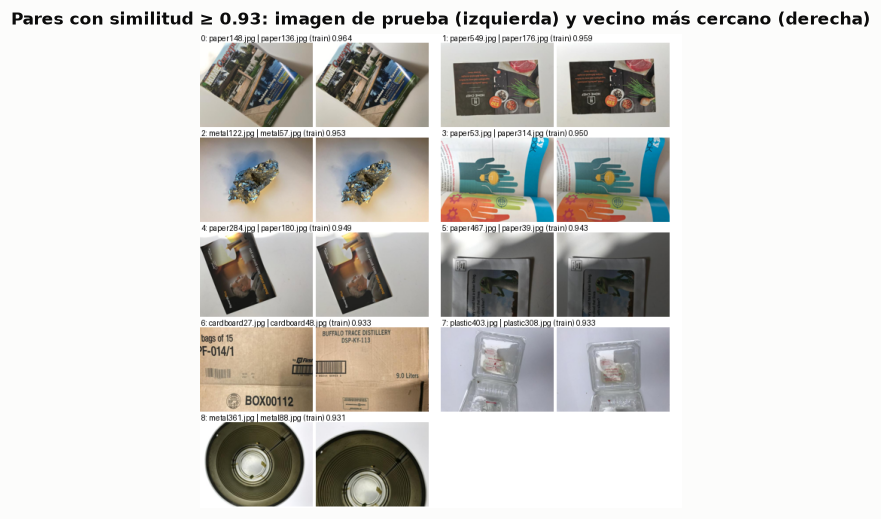

In [8]:
from PIL import Image as _I
fig, ax = plt.subplots(figsize=(9, 5.6))
ax.imshow(_I.open(COMP / "_casi_duplicados_candidatos.png")); ax.axis("off")
ax.set_title("Pares con similitud ≥ 0.93: imagen de prueba (izquierda) y vecino más cercano (derecha)")
plt.show()

Los pares con similitud alta son, en su mayoría, el mismo objeto fotografiado dos veces: algunos casi idénticos (por ejemplo, `paper148`–`paper136` o `paper549`–`paper176`) y otros con un cambio de pose o encuadre (`metal361`–`metal88`, `glass419`–`glass425`). TrashNet contiene varias vistas de algunos objetos, y sin metadatos de objeto la agrupación del capítulo 2 solo capturó las fotografías casi idénticas. Por encima del umbral, 9 imágenes de prueba (2.5 %) superan la verificación y la proporción queda por debajo de la tolerancia. La revisión visual muestra, sin embargo, que la dependencia por objeto se extiende por debajo del umbral. Por eso reportamos el desempeño con y sin esos casos.

In [9]:
sen = pd.read_csv(COMP / "casi_duplicados_sensibilidad.csv")
tabla = sen.pivot(index="model", columns="conjunto", values="f1_media")[["todas (361)", "sin sim >= 0.88", "sin sim >= 0.80"]]
tabla["caída sin ≥ 0.80"] = tabla["todas (361)"] - tabla["sin sim >= 0.80"]
rk = sen.pivot(index="model", columns="conjunto", values="rango")
tabla["rango (361)"] = rk["todas (361)"].astype(int); tabla["rango (sin ≥ 0.80)"] = rk["sin sim >= 0.80"].astype(int)
display(tabla.sort_values("todas (361)", ascending=False).round(3))
d0 = tabla.loc["RWCNet", "todas (361)"] - tabla.loc["ResNet-18", "todas (361)"]
d1 = tabla.loc["RWCNet", "sin sim >= 0.80"] - tabla.loc["ResNet-18", "sin sim >= 0.80"]
print(f"Diferencia RWCNet - ResNet-18: {d0:.3f} con las 361 imágenes y {d1:.3f} sin las 95 imágenes con similitud >= 0.80")

conjunto,todas (361),sin sim >= 0.88,sin sim >= 0.80,caída sin ≥ 0.80,rango (361),rango (sin ≥ 0.80)
model,,,,,,
RWCNet,0.945,0.943,0.933,0.012,1,1
ViT-B16,0.938,0.935,0.925,0.012,2,2
GFN,0.921,0.918,0.908,0.013,3,3
Celik-HC,0.914,0.911,0.901,0.013,4,4
ResMsCapsule,0.899,0.895,0.879,0.020,5,5
ResNet-18,0.863,0.856,0.836,0.026,6,6
MbXception,0.861,0.855,0.832,0.029,7,7
CNN,0.826,0.822,0.812,0.014,8,8
FocusRCNet,0.811,0.804,0.784,0.027,9,9


Diferencia RWCNet - ResNet-18: 0.082 con las 361 imágenes y 0.096 sin las 95 imágenes con similitud >= 0.80


El orden de los diez modelos no cambia al excluir las imágenes con un vecino parecido, y las diferencias entre los modelos preentrenados y el modelo de referencia se mantienen o aumentan. El F1 absoluto baja entre 0.01 y 0.03; la caída es mayor en cuatro de los cinco modelos entrenados desde cero (0.026 a 0.033, frente a 0.012 a 0.020 en los preentrenados), que se benefician más de haber visto otra vista del mismo objeto en entrenamiento. Concluimos que la dependencia por objeto infla ligeramente el desempeño absoluto, sobre todo en los modelos entrenados desde cero, y no altera las comparaciones. La tratamos como amenaza a la validez en el capítulo 16. Mantener la partición v2 preserva la comparación directa con los modelos base del capítulo 7. La agrupación por objeto con *embeddings* que introduce esta auditoría queda disponible para construir la partición de la etapa siguiente.

**Fuga por transformaciones.** Las únicas estadísticas ajustadas sobre los datos son la media y la desviación estándar por canal y los pesos de clase. La función `prepare_common` del código las calcula con los índices de entrenamiento y las guarda una sola vez (`results/common/norm_stats.pkl`, campo `computed_on = train`). El escalado de temperatura y la selección de época usan solo validación; XGBoost (Celik-HC) se ajusta con los *embeddings* de entrenamiento.

In [10]:
import inspect
from src import data as D
src = inspect.getsource(D.prepare_common)
print("\n".join(l for l in src.splitlines() if "channel_stats" in l or "class_weights(" in l))

    norm = channel_stats(load_cache(), sp["train"]["rows"])
    cw = {"weights": class_weights(sp["train"]["y"]), "classes": C.CLASSES,


**Prueba de sanidad con etiquetas aleatorias.** Repetimos 30 veces el pipeline completo del baseline clásico (descriptores, gradient boosting con la configuración elegida) con las etiquetas de entrenamiento permutadas. Si la partición o el preprocesamiento filtraran información de prueba, el F1 de prueba quedaría por encima del azar. El baseline clásico comparte con las redes profundas la partición, la lectura de imágenes y el preprocesamiento, que son los puntos donde podría ocurrir la fuga. Por eso sirve como prueba del pipeline de datos. Para las redes aplicamos además la prueba de permutación condicional de la sección 14.1.

In [11]:
perm = pd.read_csv(COMP / "sanidad_etiquetas_permutadas.csv")
print(f"F1 macro de prueba con etiquetas permutadas (30 réplicas): media {perm.f1_macro_test.mean():.3f}, "
      f"DE {perm.f1_macro_test.std():.3f}, máximo {perm.f1_macro_test.max():.3f}")
print("Referencia: F1 macro esperado de un clasificador aleatorio con 6 clases ≈ 0.16")

F1 macro de prueba con etiquetas permutadas (30 réplicas): media 0.152, DE 0.017, máximo 0.211
Referencia: F1 macro esperado de un clasificador aleatorio con 6 clases ≈ 0.16


**Resumen de la auditoría.**

| Verificación | Resultado | Criterio | ¿Aprueba? |
|---|---|---|---|
| Intersección de grupos, rutas y SHA-256 entre particiones | Ver tabla de intersecciones | Intersección vacía en las tres parejas | Ver celda |
| Duplicados exactos | SHA-256 recalculado de cada imagen | Cero colisiones y cero discrepancias | Ver celda |
| Casi-duplicados (similitud de *embeddings* ≥ 0.93) | Ver celda de casi-duplicados | Proporción menor que la tolerancia (5 %) y reporte del desempeño con y sin esos casos | Ver celda |
| Fuga temporal y espacial | No aplica: sin marcas de tiempo ni coordenadas | — | No aplica |
| Fuga por transformaciones | Normalización y pesos de clase con índices de entrenamiento | Ningún ajuste con validación o prueba | Sí |
| Fuga por atributos | No aplica: la entrada es solo la imagen; el atajo de fondo se trata en el capítulo 15 | — | No aplica |
| Validación adversarial | AUC entrenamiento frente a prueba (tabla anterior) | AUC no distinguible de 0.5 | Ver celda |
| Fuga por modelos preentrenados | ImageNet-1k se construyó entre 2009 y 2012 a partir de imágenes de internet; TrashNet se fotografió en 2016–2017 y no forma parte de ImageNet | Riesgo bajo, declarado | Sí |
| Etiquetas aleatorias | F1 de prueba con etiquetas permutadas | Cercano al azar | Ver celda |

La celda siguiente completa la columna de decisión con los valores calculados.

In [12]:
inter = pd.DataFrame(res)
ok_inter = bool((inter[["grupos compartidos", "rutas compartidas", "SHA-256 compartidos"]] == 0).all().all())
ok_sha = (len(malos) == 0) if RAW.exists() else None
n_casi = int((emb.similitud >= 0.93).sum())
ok_casi = n_casi / 361 < 0.05
auc_tt = adv.loc[0, "AUC"]; p_tt = adv.loc[0, "p_permutación"]
resumen = pd.DataFrame([
    ("Intersección de identificadores", f"{int(inter.iloc[:, 1:].to_numpy().sum())} coincidencias", ok_inter),
    ("Duplicados exactos y huella de prueba", f"huella coincide: {huella == registrada}; SHA-256 distintos: {len(malos) if RAW.exists() else 'n/d'}", ok_sha and huella == registrada),
    ("Casi-duplicados (similitud >= 0.93)", f"{n_casi} de 361; orden de los modelos sin cambios al excluirlos", ok_casi),
    ("Validación adversarial entrenamiento–prueba", f"AUC {auc_tt:.3f}, p = {p_tt:.3f}", p_tt >= 0.05),
    ("Etiquetas aleatorias", f"F1 medio {perm.f1_macro_test.mean():.3f}", perm.f1_macro_test.max() < 0.30),
], columns=["verificación", "resultado", "aprueba"])
display(resumen)

,verificación,resultado,aprueba
0,Intersección de identificadores,0 coincidencias,True
1,Duplicados exactos y huella de prueba,huella coincide: True; SHA-256 distintos: 0,True
2,Casi-duplicados (similitud >= 0.93),9 de 361; orden de los modelos sin cambios al ...,True
3,Validación adversarial entrenamiento–prueba,"AUC 0.500, p = 0.473",True
4,Etiquetas aleatorias,F1 medio 0.152,True


Las verificaciones aplicables se aprueban. La auditoría de casi-duplicados encuentra, además, una dependencia por objeto que la partición no controla por completo; su efecto se cuantificó arriba y no cambia las conclusiones. La única diferencia con el capítulo 1 es de empaquetado. El archivo `dataset-resized.zip` descargado para el benchmark tiene un SHA-256 distinto (`0bf47279…`) del registrado en la sección 1.6 (`c060e8ab…`), pero el SHA-256 de cada una de las 2521 imágenes coincide con el de la partición y la huella del conjunto de prueba es la misma. El contenido evaluado es idéntico. El archivo de partición del repositorio de entrenamiento difiere del de este repositorio solo en los finales de línea; sus 2521 asignaciones son idénticas.